# Project 3. CLD Aggregation Tool

Last update: 05/21/2024

Title: Streamlining the Aggregation of Causal Loop Diagrams: A Thematic Labeling and Adjacency Matrix Approach

Overview: 
Spaghetti Causal Loop Diagrams (CLDs) present a significant challenge for modelers in effectively communicating complex system dynamics to stakeholders. Traditionally, modelers manually synthesize multiple CLDs to create an aggregated diagram that provides a higher-level understanding of the system. This paper introduces a streamlined procedure for aggregating CLDs using general categorical labels. 

The methodology involves translating qualitative mental models into adjacency matrices that capture both links and polarity signs, manually coding and substituting variable names with thematic labels, aggregating these matrices to identify significant feedback loops, and validating the approach by comparing it with the manual synthesis performed by an expert system dynamicist. 

Our results demonstrate that this tool is highly useful for group model-building experts, particularly when dealing with a large number of mental maps. The proposed method enhances the clarity and efficiency of synthesizing complex CLDs, thereby improving the overall communication of system dynamics.







In [1]:
%load_ext autoreload
%autoreload 2

In [6]:
import numpy as np
import os 
import pickle
import pandas as pd
import sys
import networkx as nx

# Add the src directory to the sys.path
sys.path.append(os.path.abspath(os.path.join('..', 'src')))

# Import the function from data_io.py
# from parse_cld import get_dataframe, get_adjacency_matrix, get_polarity_matrix
# import parse_cld 
# import cld_nx

import parse_cld
import cld_nx
import data_io


In [26]:
# Set the new directory
new_dir = "/Users/gl665/PycharmProjects/Phrame_MentalMaps"
# Change the current working directory
os.chdir(new_dir)

print(os.getcwd())

/Users/gl665/PycharmProjects/Phrame_MentalMaps


In [27]:
# Read all the json files in 
my_data_RC = {}
folder_path = 'Output/SYNCH/JSON_file/RC/'

my_data_RC = data_io.read_json(folder_path, my_data_RC)

Output/SYNCH/JSON_file/RC/FM 51220Clean.json
load: FM 51220Clean.json
Output/SYNCH/JSON_file/RC/Passages Clean.json
load: Passages Clean.json
Output/SYNCH/JSON_file/RC/full circle GBM 5 24 21clean.json
load: full circle GBM 5 24 21clean.json
Output/SYNCH/JSON_file/RC/C 7 6 20 clean model.json
load: C 7 6 20 clean model.json
Output/SYNCH/JSON_file/RC/tracy clean model.json
load: tracy clean model.json
Output/SYNCH/JSON_file/RC/Wavi combined clean.json
load: Wavi combined clean.json
Output/SYNCH/JSON_file/RC/drug justice model clean.json
load: drug justice model clean.json
Output/SYNCH/JSON_file/RC/7 13 20 clean model.json
load: 7 13 20 clean model.json
Output/SYNCH/JSON_file/RC/DSS23.json
load: DSS23.json
Output/SYNCH/JSON_file/RC/E clean model 572020.json
load: E clean model 572020.json
Output/SYNCH/JSON_file/RC/nat model clean2.json
load: nat model clean2.json
Output/SYNCH/JSON_file/RC/j model 7 13 20 clean model3.json
load: j model 7 13 20 clean model3.json
Output/SYNCH/JSON_file/RC/

In [131]:
# file_rename = pd.read_excel('Output/SYNCH/file_rename/RC_file_rename.xlsx', index_col=0)
# file_rename['file_no.'] = [i+1 for i in range(len(file_rename.index))]
# file_rename.head(3)



In [ ]:
# preprocess the RC_Updated_Themes.xslx and match it back with the RC files. 

# df_rc_themes = pd.read_excel('Dataset/SYNCH/aggregate_theme/RC_Updated_Themes.xlsx', sheet_name= "clean")

# # get column 1 and 4
# df_aggregate_names = df_rc_themes.iloc[:, [1, 4]]

# df_aggregate_names.columns = ['theme', 'variable']
# # delete rows if both are column values are nan 
# df_aggregate_names = df_aggregate_names.dropna(subset=['theme', 'variable'], how='all')


# df_aggregate_names['theme'] = df_aggregate_names['theme'].fillna(method='ffill')

# df_aggregate_names['theme']= df_aggregate_names['theme'].str.lower()
# df_aggregate_names['variable']= df_aggregate_names['variable'].str.lower()

# df_aggregate_names.head(20)
# df_aggregate_names.to_csv('Dataset/SYNCH/aggregate_theme/RC_theme_var_matching.csv', index=False)

In [32]:

df_aggregate_names = pd.read_csv('Dataset/SYNCH/aggregate_theme/RC_theme_var_matching.csv')
df_aggregate_names.head()

,theme,variable
0,healthy development,child psychological development
1,healthy development,healthy child development
2,healthy development,child behavioral issues
3,healthy development,child physcial violent perpetration
4,healthy development,developmental delay in child


In [54]:
my_data_RC['Passages Clean.json']

[{1: 'accountablility',
  2: 'alcohol exposed pregnancy',
  3: 'alcohol misuse',
  4: 'coping skills',
  5: 'death',
  6: 'dire situtations',
  7: 'drugs',
  8: 'family and child loss (legal)',
  9: 'family emotional health',
  10: 'healing',
  11: 'higher power',
  12: 'intimate partner violence',
  13: 'jail',
  14: 'mental health',
  15: 'negative partners (broken person)',
  16: 'passages (re-entry facility)',
  17: 'structure and love',
  18: 'supportive people'},
 {3: {12: {'weight': 1},
   9: {'weight': -1},
   6: {'weight': 1},
   14: {'weight': -1},
   13: {'weight': 3},
   2: {'weight': 1},
   7: {'weight': 1},
   8: {'weight': 1},
   18: {'weight': -1}},
  12: {3: {'weight': 1},
   15: {'weight': 1},
   6: {'weight': 3},
   14: {'weight': -1},
   13: {'weight': 1},
   5: {'weight': 1},
   7: {'weight': 1},
   8: {'weight': 1},
   18: {'weight': -1}},
  15: {12: {'weight': 1}},
  14: {3: {'weight': -1},
   12: {'weight': -1},
   4: {'weight': 1},
   11: {'weight': 1},
   18: 

In [61]:
dict_pol_mx = {}
for key, value in my_data_RC.items():
    print(key)
    merge_df,  theme_dict = parse_cld.get_theme_cld(value, df_aggregate_names)
    adj_mx = parse_cld.get_aggregate_adjacency_mx(merge_df,  theme_dict)
    pol_mx = parse_cld.get_aggregate_polarity_mx (merge_df, theme_dict)
    # print(pol_mx.shape)
    dict_pol_mx[key] = pol_mx 



#  pol_max_combined = parse_cld.get_combine_matrix(pol_mx, )

FM 51220Clean.json
Passages Clean.json
full circle GBM 5 24 21clean.json
C 7 6 20 clean model.json
tracy clean model.json
Wavi combined clean.json
drug justice model clean.json
7 13 20 clean model.json
DSS23.json


IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer

In [11]:
df_theme_dict = pd.DataFrame.from_dict(theme_dict, orient='index')
df_theme_dict.to_csv("theme_dict.csv")

In [12]:
# pol_max_combined = pd.DataFrame()
df = pd.DataFrame()

# combined all the dataframe in  dict_pol_mx using get_combined_matrix 
for key, value in dict_pol_mx.items():
    print(key)
    pol_max_combined = parse_cld.get_combine_matrix(value, df)

print(pol_max_combined.shape)

FM 51220Clean.json
Passages Clean.json
full circle GBM 5 24 21clean.json
Wavi combined clean.json
drug justice model clean.json
7 13 20 clean model.json
DSS23.json
E clean model 572020.json
nat model clean2.json
FC Prov Clean.json
full circle clean.json
reentry clean model.json
DV justice model clean.json
(72, 72)


In [13]:
pol_max_combined

to,alc m,child home function,self defense,report ipv,ipv reportable incidents,likelihood of arrest,stigma of victimization,ipv stigma,prior rez justice experience,understanding of non-rez justice,...,reentry resource quality,mental health,exposure to violence,jail/incarceration,reproductive health/relationship education resources,likelihood of ipv charge,accessability of victims resources,cultural mistrust of institutions and institutionally provided resources,reluctance to report ipv,indigeous barriers/obtaining success and health
from,,,,,,,,,,,,,,,,,,,,,
alc m,0,0,0,0,0,0,0,0,0,0,...,0,-1,0,0,0,0,0,0,0,0
child home function,1,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
self defense,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
report ipv,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ipv reportable incidents,0,0,0,3,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
likelihood of ipv charge,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
accessability of victims resources,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,3,0,0,0
cultural mistrust of institutions and institutionally provided resources,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
print(pol_max_combined.shape)

# Check if the matrix is sqaure 
if (pol_max_combined.shape[0] == pol_max_combined.shape[1]): 
    print("true")
else: 
    print('false')

# pol_max_combined.to_excel('tt.xlsx')



(72, 72)
true


In [15]:
# delete rows and columns that are nan 
pol_max_combined = pol_max_combined.dropna(axis=0, how='all')
pol_max_combined = pol_max_combined.dropna(axis=1, how='all')

# print all rows 
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

pol_max_combined 

to,alc m,child home function,self defense,report ipv,ipv reportable incidents,likelihood of arrest,stigma of victimization,ipv stigma,prior rez justice experience,understanding of non-rez justice,time ratio between charges/prosecution\\,adjustment self sufficiency skills,relationship functioning,advocate care to victims,natural supports,minimization/underreporting of event,stigma of victimization,legal requirement for arrest,report ipv,ipv offender rehabilitation,available mental health in-jail resources,re-entry resources,re-entry adjustment,stigma of \reputation\,education on consent,likelihood of conviction,offender/victim drug and alcohol use,\credibility\ of incident,time ratio between charges/prosecution\\,self defense,alc m,childcare need,ability for victims to recieve housing resources,education,natural supports,ability to sustain self/kids,ability to sustain self/kids,advocate case load,physical violence,reproductive health,child sexual violence,concern for child health,child physical violence,child sexual violence,child physical violence,using mental health in-jail resources,attaining housing resources,seeking housing resources,child physical violence,child sexual violence,overall resource accessibility,family behaviors and norms around ipv and violence,deterrents from ipv reporting,likelihood of ending ipv relationship,individual/family self sustainment,dependence on others to meet needs,perceived credibilty of ipv report,level of basic needs unmet,ipv,severity of incident,effectiveness/quality of policing & justice system,family functioning,reentry resource quality,mental health,exposure to violence,jail/incarceration,reproductive health/relationship education resources,likelihood of ipv charge,accessability of victims resources,cultural mistrust of institutions and institutionally provided resources,reluctance to report ipv,indigeous barriers/obtaining success and health
from,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
alc m,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-1,0,-1,0,0,0,0,0,0,0,0
child home function,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-1,0,0,0,0,1,0,0,1,0,0,0,0,0
self defense,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
report ipv,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
ipv reportable incidents,0,0,0,3,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
likelihood of arrest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0
stigma of victimization,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
ipv stigma,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
prior rez justice experience,0,0,0,0,0,0,0,0,0,-1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [16]:
import networkx as nx

# Assuming you have a DataFrame 'df' with NaN values in column names or index labels
pol_max_combined = pol_max_combined.rename(columns=lambda x: str(x) if pd.notnull(x) else 'missing_column')
pol_max_combined = pol_max_combined.rename(index=lambda x: str(x) if pd.notnull(x) else 'missing_index')

# delete rows and column that the name is missing_column 
pol_max_combined = pol_max_combined.drop(['missing_column'], axis=1)
pol_max_combined = pol_max_combined.drop(['missing_index'], axis=0)



KeyError: "['missing_column'] not found in axis"

In [102]:
pol_max_combined.to_excel('pol_max_combined.xlsx')


In [ ]:

pol_max_combined = pd.read_excel('pol_max_combined.xlsx')
pol_max_combined.index = pol_max_combined['from']
# delete first column 
pol_max_combined = pol_max_combined.drop(columns=['from'])

In [ ]:

# fill nan with 0 
# pol_max_combined = pol_max_combined.fillna(0)
# pol_max_combined
# Create a NetworkX graph from the cleaned DataFrame
G = nx.from_pandas_adjacency(df)



In [17]:
G= nx.from_pandas_adjacency(pol_max_combined, create_using=nx.DiGraph)

NetworkXError: Adjacency matrix not square: nx,ny=(72, 98)

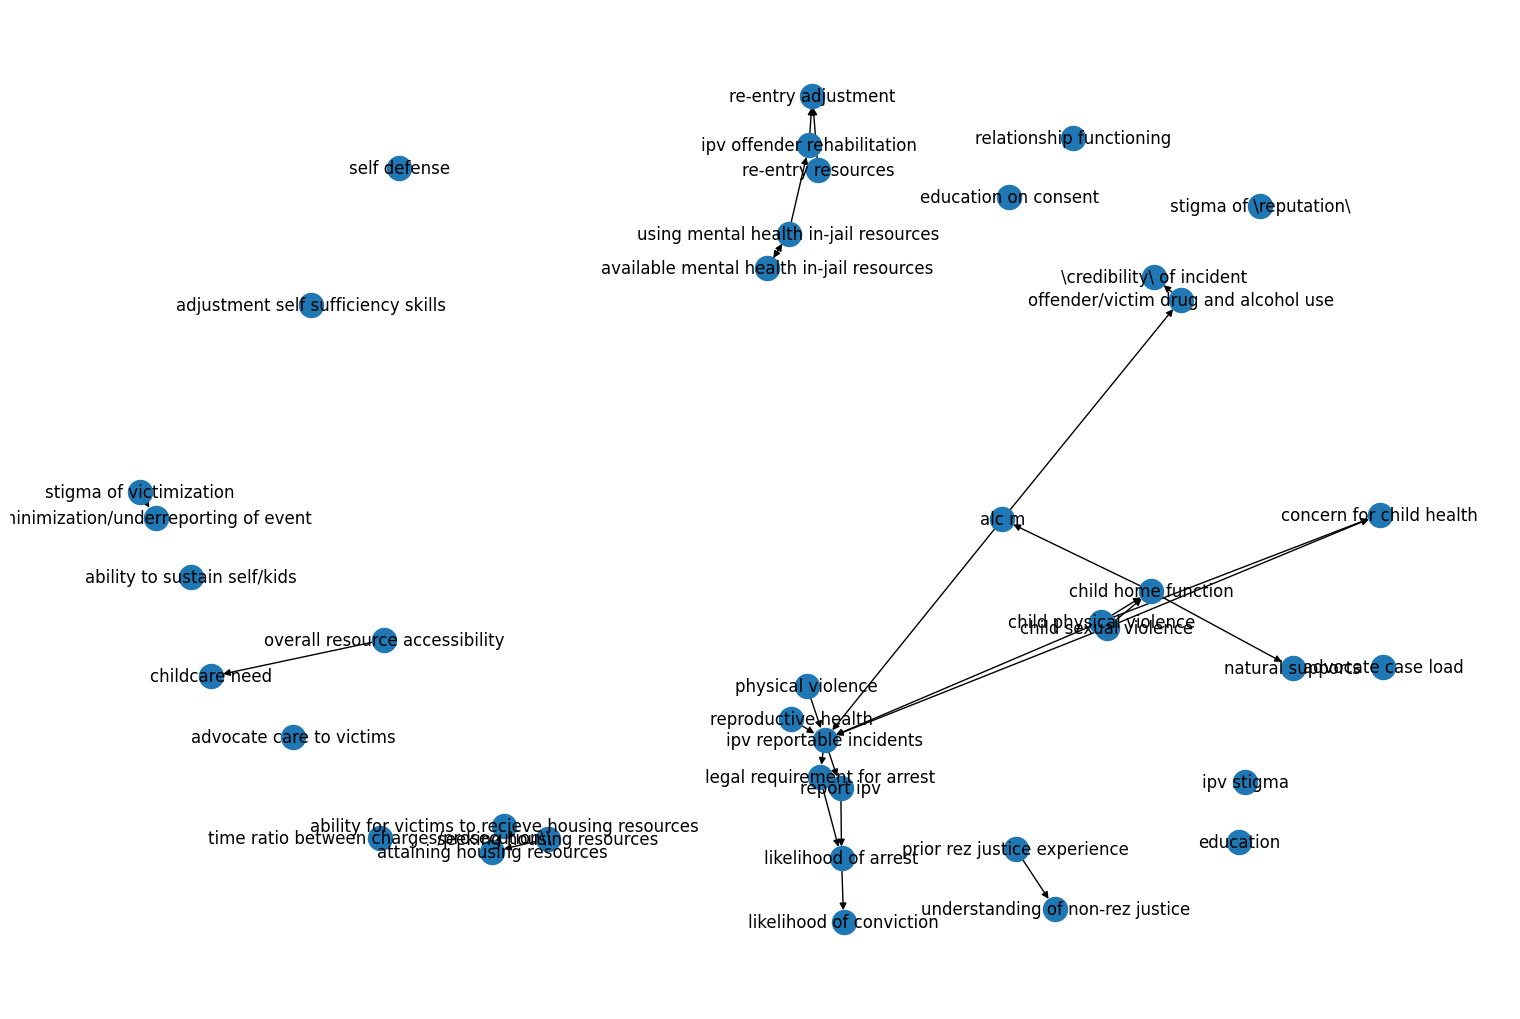

In [140]:
import matplotlib.pyplot as plt

# create a larger plot 
plt.figure(figsize=(15,10))
nx.draw(G,with_labels = True)
plt.draw()

## get one pol_mx using the get_theme_cld function

In [74]:
my_data_RC['DSS23.json']

[{1: 'accuracy of assessment',
  2: 'aces',
  3: 'aep',
  4: 'alc norms',
  5: 'alcohol misuse',
  6: 'attourney buy-in',
  7: 'attourney perception',
  8: 'attourney skill',
  9: 'behavioral change',
  10: 'build social supports',
  11: 'case load',
  12: 'caseworker relationship',
  13: 'child removal from home',
  14: 'child welfare intervenes',
  15: 'child witness ipv',
  16: 'childhood home functioning',
  17: 'client buy-in',
  18: 'closed case',
  19: 'court mandate',
  20: 'cultural mistrust',
  21: 'drug use',
  22: 'dss assessment process',
  23: 'dss case management',
  24: 'dss custody',
  25: 'dss referral to resources',
  26: 'dss requirements achieved',
  27: 'ease of assessment',
  28: 'economic support',
  29: 'efficacy of resources',
  30: 'frustration with process',
  31: 'ipv',
  32: 'ipv norms',
  33: 'jail',
  34: 'judge continuance grant',
  35: 'judge perception',
  36: 'knowledge of resources',
  37: 'legal housing',
  38: 'mental health needs',
  39: 'mental 

In [73]:
dict_vars, df = parse_cld.get_dataframe(my_data_RC['DSS23.json'])

df

,from,to,polarity_type,links
0,16.0,2.0,3.0,1
1,16.0,38.0,3.0,1
2,16.0,4.0,3.0,1
3,16.0,32.0,3.0,1
4,16.0,13.0,3.0,1
5,2.0,38.0,3.0,1
6,2.0,16.0,3.0,1
7,38.0,31.0,3.0,1
8,38.0,5.0,3.0,1
9,38.0,40.0,3.0,1


In [72]:
merge_df, theme_dict = parse_cld.get_theme_cld(my_data_RC['DSS23.json'], df_aggregate_names)



adj_mx = parse_cld.get_aggregate_adjacency_mx(merge_df, theme_dict)
pol_nx = parse_cld.get_aggregate_polarity_mx(merge_df, theme_dict)

merge_df



                                                theme  \
0                                                 NaN   
1                                                aces   
2                           alcohol exposed pregnancy   
3                                                 NaN   
4                                  alcohol use/misuse   
5                 attourney ability for reunification   
6                 attourney ability for reunification   
7                 attourney ability for reunification   
8                                                 NaN   
9                                                 NaN   
10                                                NaN   
11                                                NaN   
12              likelihood of child removal from home   
13                                                NaN   
14                               exposure to violence   
15                                 family functioning   
16                             

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer

In [29]:
# change theme_dict keys to int 
theme_dict

{1: 'accountablility',
 2: 'alcohol exposed pregnancy',
 3: 'alcohol use/misuse',
 19: 'individual protective coping skills',
 5: 'emotional distress',
 6: 'dire situtations',
 7: 'drugs',
 8: 'likelihood of child removal from home',
 9: 'family functioning',
 10: 'healing',
 12: 'intimate partner violence',
 13: 'jail/incarceration',
 14: 'mental health',
 15: 'relationship functioning',
 16: 'passages (re-entry facility)',
 17: 'overall resource quality',
 18: 'supportive people'}

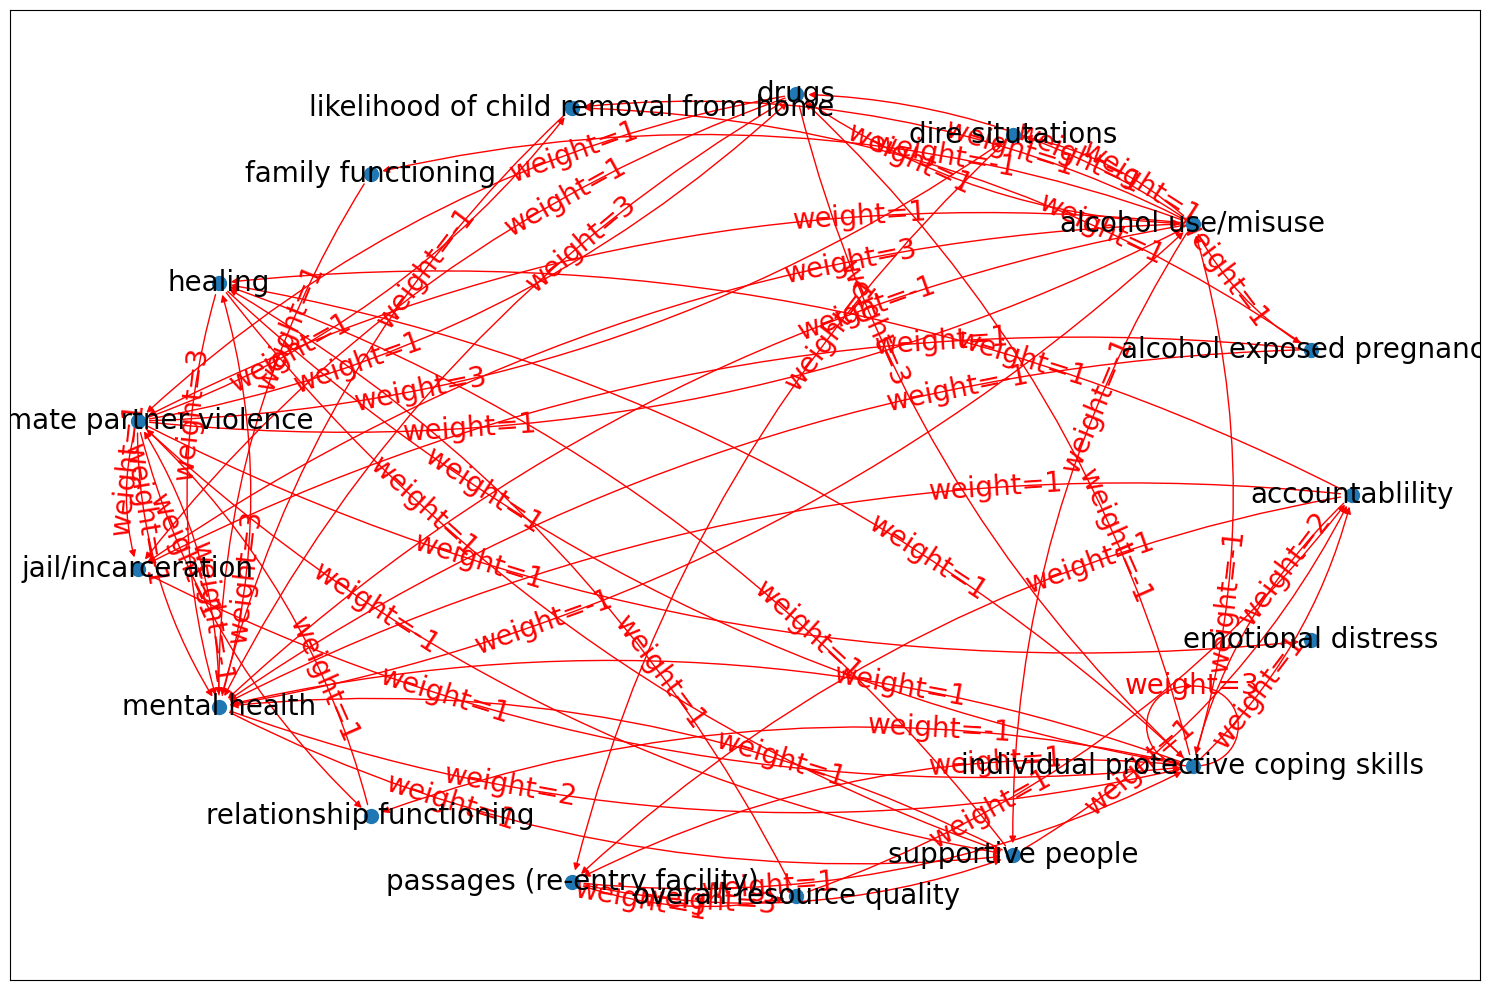

In [30]:
df_subset = merge_df[['from', 'to', 'polarity_type']]
# Change the column name polarity type of weight 
df_subset = df_subset.rename(columns={'polarity_type': 'weight'})

d = parse_cld.get_dict_of_dicts(df_subset)
# print(d)
G_test = nx.MultiDiGraph(d)
# print(dict_var)
cld_nx.draw_labeled_multigraph(G_test, "weight", theme_dict)

In [31]:
adj_mx

to,accountablility,alcohol exposed pregnancy,alcohol use/misuse,emotional distress,dire situtations,drugs,likelihood of child removal from home,family functioning,healing,intimate partner violence,jail/incarceration,mental health,relationship functioning,passages (re-entry facility),overall resource quality,supportive people,individual protective coping skills
from,,,,,,,,,,,,,,,,,
accountablility,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,2
alcohol exposed pregnancy,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0
alcohol use/misuse,0,1,0,0,1,1,1,1,0,1,1,1,0,0,0,1,0
emotional distress,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
dire situtations,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
drugs,0,0,1,0,0,0,0,0,0,1,1,1,0,0,0,0,1
likelihood of child removal from home,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
family functioning,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
healing,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1


In [ ]:
pol_nx.shape

(21, 21)

In [22]:
# pol_nx
G= nx.from_pandas_adjacency(pol_nx, create_using=nx.DiGraph)
# create a larger plot 
plt.figure(figsize=(15,10))
nx.draw(G,with_labels = True)
plt.draw()

NetworkXError: Adjacency matrix not square: nx,ny=(21, 31)

## Get an aggregated CLD for one single CLD 

In [34]:
dict_vars, df = parse_cld.get_dataframe(my_data_RC['Passages Clean.json'])

df

,from,to,polarity_type,links
0,3,12,1,1
1,3,9,-1,1
2,3,6,1,1
3,3,14,-1,1
4,3,13,3,1
5,3,2,1,1
6,3,7,1,1
7,3,8,1,1
8,3,18,-1,1
9,12,3,1,1


In [35]:
dict_vars

{1: 'accountablility',
 2: 'alcohol exposed pregnancy',
 3: 'alcohol misuse',
 4: 'coping skills',
 5: 'death',
 6: 'dire situtations',
 7: 'drugs',
 8: 'family and child loss (legal)',
 9: 'family emotional health',
 10: 'healing',
 11: 'higher power',
 12: 'intimate partner violence',
 13: 'jail',
 14: 'mental health',
 15: 'negative partners (broken person)',
 16: 'passages (re-entry facility)',
 17: 'structure and love',
 18: 'supportive people'}

Take "Rapid City Update Themes" Excel Sheet "Clean" column B for Aggregated Variable Name and column E for orignial Variable name

In [36]:
# create a dataframe for the single cld var name and the theme 
# create a pd datframe 
vars_cld = pd.DataFrame.from_dict(dict_vars, orient='index').reset_index()
# rename columns 
vars_cld.columns = ['vensim_var_no','var_name']
# turn all the variable names to lowercap 
vars_cld['var_name'] = vars_cld['var_name'].str.lower()
# delete the "" sign 
vars_cld['var_name'] = vars_cld['var_name'].str.replace('"', '')
vars_cld

,vensim_var_no,var_name
0,1,accountablility
1,2,alcohol exposed pregnancy
2,3,alcohol misuse
3,4,coping skills
4,5,death
5,6,dire situtations
6,7,drugs
7,8,family and child loss (legal)
8,9,family emotional health
9,10,healing


In [39]:
# merge the two dataframes and find the theme name for the cld 
df_aggregate_merge = pd.merge(df_aggregate_names, vars_cld, left_on='variable', right_on='var_name', how='right')
df_aggregate_merge

,theme,variable,vensim_var_no,var_name
0,NaN,NaN,1,accountablility
1,NaN,NaN,2,alcohol exposed pregnancy
2,alcohol use/misuse,alcohol misuse,3,alcohol misuse
3,individual protective coping skills,coping skills,4,coping skills
4,emotional distress,death,5,death
5,NaN,NaN,6,dire situtations
6,NaN,NaN,7,drugs
7,likelihood of child removal from home,family and child loss (legal),8,family and child loss (legal)
8,family functioning,family emotional health,9,family emotional health
9,NaN,NaN,10,healing


In [38]:
# merging the cld. Count the duplicate themes. 

df_aggregate_merge['vensim_var_no'] = df_aggregate_merge['vensim_var_no'].astype(int)
# create a new variable number for the theme 

# def get_duplicate_theme_no(df):
#     # get all the duplicate theme no 
#     df_theme_no = df['theme'].value_counts()
#     duplicate_theme_no = df_theme_no[df_theme_no > 1].index.tolist()
#     return duplicate_theme_no

list_of_duplicate_themes = parse_cld.get_duplicate_theme_no(df_aggregate_merge)
print(list_of_duplicate_themes)


['individual protective coping skills']


In [40]:

# create a dictionary where the keys is the orignial var_no and the new var_no is the theme_no

theme_no_dict = {}
for i, val in enumerate(list_of_duplicate_themes):
    theme_no_dict[val] = max(df_aggregate_merge['vensim_var_no']) + i + 1

df_aggregate_merge['theme_no'] = df_aggregate_merge['theme'].map(theme_no_dict)


for i, row in df_aggregate_merge.iterrows():
    if pd.isna(row['theme_no']):
        df_aggregate_merge.at[i, 'theme_no'] = row['vensim_var_no']


df_aggregate_merge['theme_no'] = df_aggregate_merge['theme_no'].astype(int)

df_aggregate_merge




,theme,variable,vensim_var_no,var_name,theme_no
0,NaN,NaN,1,accountablility,1
1,NaN,NaN,2,alcohol exposed pregnancy,2
2,alcohol use/misuse,alcohol misuse,3,alcohol misuse,3
3,individual protective coping skills,coping skills,4,coping skills,19
4,emotional distress,death,5,death,5
5,NaN,NaN,6,dire situtations,6
6,NaN,NaN,7,drugs,7
7,likelihood of child removal from home,family and child loss (legal),8,family and child loss (legal),8
8,family functioning,family emotional health,9,family emotional health,9
9,NaN,NaN,10,healing,10


In [47]:
# create a new dictionary the keys in the vensim vars no, the values is the theme column, if the value is nan, the value is variable 
theme_dict = {}
for index, row in df_aggregate_merge.iterrows():
    if pd.isna(row['theme']):
        theme_dict[row['theme_no']] = row['var_name']
    else:
        theme_dict[row['theme_no']] = row['theme']
        
theme_dict = {int(k): v for k, v in theme_dict.items()}

theme_dict

{1: 'accountablility',
 2: 'alcohol exposed pregnancy',
 3: 'alcohol use/misuse',
 19: 'individual protective coping skills',
 5: 'emotional distress',
 6: 'dire situtations',
 7: 'drugs',
 8: 'likelihood of child removal from home',
 9: 'family functioning',
 10: 'healing',
 12: 'intimate partner violence',
 13: 'jail/incarceration',
 14: 'mental health',
 15: 'relationship functioning',
 16: 'passages (re-entry facility)',
 17: 'overall resource quality',
 18: 'supportive people'}

In [43]:
theme_org_new_dict = dict(zip(df_aggregate_merge['vensim_var_no'], df_aggregate_merge['theme_no']))

new_df = df.copy()
# change all data in df to int 
new_df = new_df.astype(int)
#swap the from column in df to new number based on theme_no_number_dict
new_df['from'] = new_df['from'].map(theme_org_new_dict)
new_df['to'] = new_df['to'].map(theme_org_new_dict)

merge_df = new_df.groupby(['from', 'to']).sum().reset_index()

merge_df


,from,to,polarity_type,links
0,1,10,1,1
1,1,14,1,1
2,1,16,1,1
3,1,19,2,2
4,2,8,1,1
5,2,13,1,1
6,2,14,-1,1
7,3,2,1,1
8,3,6,1,1
9,3,7,1,1


In [48]:
pol_mx = parse_cld.get_adjacency_matrix(merge_df)


In [49]:
# merge the same theme frame??  

# pol_mx = parse_cld.get_adjacency_matrix(df)

pol_mx.columns = pol_mx.columns.map(theme_dict)

pol_mx.index = pol_mx.index.map(theme_dict)
pol_mx

to,accountablility,alcohol exposed pregnancy,alcohol use/misuse,emotional distress,dire situtations,drugs,likelihood of child removal from home,family functioning,healing,intimate partner violence,jail/incarceration,mental health,relationship functioning,passages (re-entry facility),overall resource quality,supportive people,individual protective coping skills
from,,,,,,,,,,,,,,,,,
accountablility,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,2
alcohol exposed pregnancy,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0
alcohol use/misuse,0,1,0,0,1,1,1,1,0,1,1,1,0,0,0,1,0
emotional distress,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
dire situtations,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
drugs,0,0,1,0,0,0,0,0,0,1,1,1,0,0,0,0,1
likelihood of child removal from home,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
family functioning,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
healing,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1


In [123]:
# pol_mx.to_csv("aggregate passage_mx.csv")

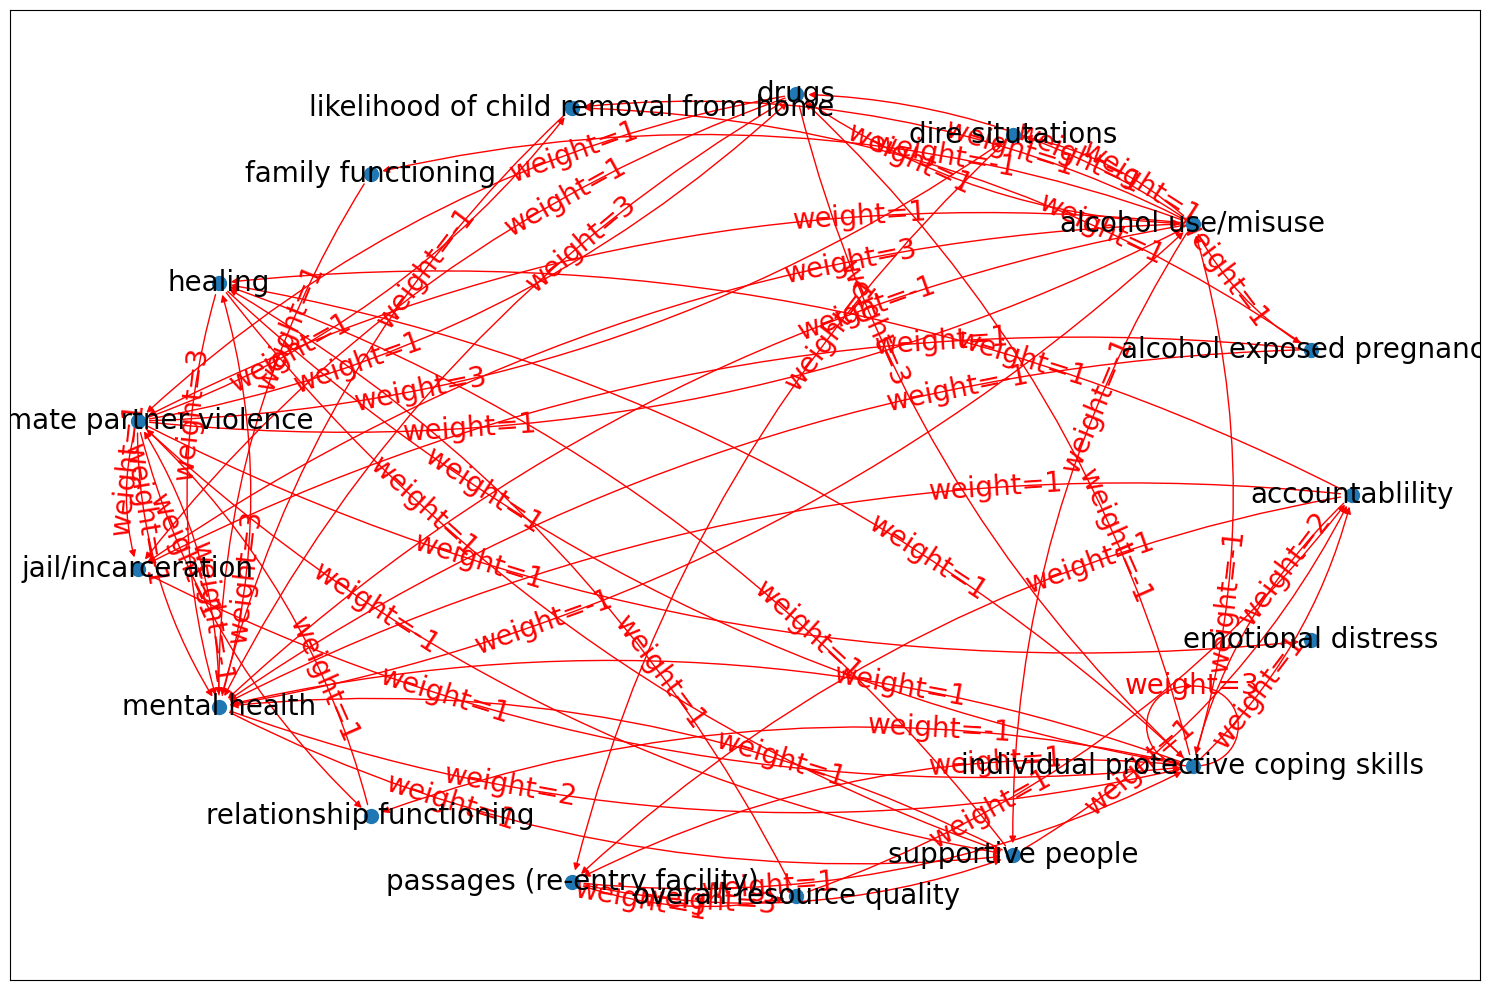

In [50]:
# merge_df
df_subset = merge_df[['from', 'to', 'polarity_type']]
# Change the column name polarity type of weight 
df_subset = df_subset.rename(columns={'polarity_type': 'weight'})

d = parse_cld.get_dict_of_dicts(df_subset)
# print(d)
G_test = nx.MultiDiGraph(d)
# print(dict_var)
cld_nx.draw_labeled_multigraph(G_test, "weight", theme_dict)

In [51]:
# G= nx.from_pandas_adjacency(pol_mx, create_using=nx.DiGraph)
# # create a larger plot 
# plt.figure(figsize=(15,10))
# nx.draw(G,with_labels = True)
# plt.draw()

## Combining Matrices 

In [117]:

matrix1 = [[ 1, 1, 1, 0, 1],
        [1, 0, 1, 1, 1],
        [ 1, 0, 0, 0, 0],
        [1, 1, 0, 1, 0],
        [1, 0, 0, 1, 0]]

matrix1 = pd.DataFrame(matrix1, columns=['a', 'b', 'c', 'd', 'e'])
matrix1.index = rows_1
print(matrix1)



matrix2 = [[ 0, 1, 1, 0, 1],
        [1, 0, 1, 1, 1],
        [ 1, 0, 0, 0, 0],
        [1, 1, 0, 1, 0],
        [1, 0, 0, 1, 1]]

matrix2 = pd.DataFrame(matrix2, columns=['z', 'd', 'c', 'b', 'a'])
matrix2.index = rows_2
print("matrix2")
print(matrix2)

   a  b  c  d  e
a  1  1  1  0  1
b  1  0  1  1  1
c  1  0  0  0  0
d  1  1  0  1  0
e  1  0  0  1  0
matrix2
   z  d  c  b  a
z  0  1  1  0  1
d  1  0  1  1  1
c  1  0  0  0  0
b  1  1  0  1  0
a  1  0  0  1  1


In [119]:
# def combine_non_nan(s1, s2):
#     # print("s1", s1)
#     # print("s2", s2)
#     if pd.isna(s1).all():
#         return s2
#     elif pd.isna(s2).all():
#         return s1
#     else:
#         return s1 + s2



# def get_combine_matrix(matrix1, matrix2): 

#     combined_matrix = matrix1.combine(matrix2, combine_non_nan, overwrite = False)
#     combined_matrix = combined_matrix.fillna(matrix1)
#     combined_matrix = combined_matrix.fillna(matrix2)

#     return combined_matrix 

combined_matrix = parse_cld.get_combine_matrix(matrix1, matrix2)
print(combined_matrix)

     a    b    c    d    e    z
a  2.0  2.0  1.0  0.0  1.0  1.0
b  1.0  1.0  1.0  2.0  1.0  1.0
c  1.0  0.0  0.0  0.0  0.0  1.0
d  2.0  2.0  1.0  1.0  0.0  1.0
e  1.0  0.0  0.0  1.0  0.0  NaN
z  1.0  0.0  1.0  1.0  NaN  0.0


In [161]:
combined_matrix_ = np.where(combined_matrix == 2, 1, combined_matrix)



(6, 7)


NameError: name 'plt' is not defined

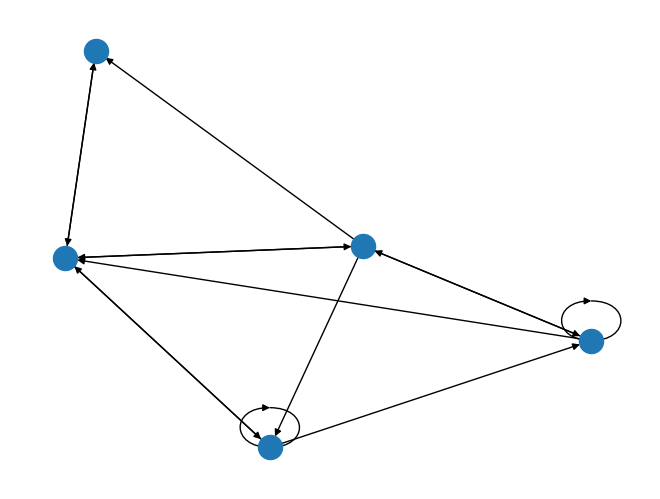

In [165]:
# import cld_nx
print(combined_matrix.shape)
combined_matrix = combined_matrix.reset_index()
G= nx.from_pandas_adjacency(matrix2, create_using=nx.DiGraph)
nx.draw(G)
plt.draw()